# Chapitre 4 - Cours 3 : Sélectionner un modèle

On ne cherche pas le meilleur modèle dans l'absolu, mais **le meilleur modèle pour son
application**. Ce notebook suit la section *Model Selection* du livre :

1. le workflow de sélection (section *Model Selection Workflow*) ;
2. filtres durs, attributs souples et front de Pareto ;
3. open source, poids ouverts et licences (section *Open source, open weight, and model licenses*) ;
4. API ou auto-hébergement : les sept axes (section *Open source models versus model APIs*) ;
5. construire ou acheter : le calcul du point mort (section *API cost versus engineering cost*) ;
6. agréger des benchmarks en classement (section *Benchmark selection and aggregation*) ;
7. les corrélations entre benchmarks ;
8. la contamination des données (section *Data contamination with public benchmarks*) ;
9. la saturation des benchmarks.

Les chiffres de catalogue, de prix et de classements sont **fictifs mais plausibles** ; seule
la matrice de corrélation (tableau 4-5 du livre) est une donnée réelle. Le seul modèle
utilisé est Qwen 0.5B, pour la détection de contamination par perplexité.

In [1]:
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kendalltau
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from matplotlib.ticker import FuncFormatter
from aie.plotting import (set_style, COLORS, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY,
                          GREEN, LIGHT, annotate_bars, subtitle, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch04_systemes as c4

set_style()
pd.set_option("display.width", 140)
rng = np.random.default_rng(0)
plain = FuncFormatter(lambda v, _: f"{v:g}")   # graduations lisibles sur les axes logarithmiques

## 1. Le workflow de sélection (section *Model Selection Workflow*)

La sélection de modèle n'a pas lieu une seule fois : on la refait à chaque étape
d'adaptation (prompt engineering, affinage...). Typiquement, on commence avec le modèle le
plus fort pour vérifier la **faisabilité**, puis on redescend vers des modèles plus petits ;
ou, pour l'affinage, on débogue sur un petit modèle avant de monter. Dans tous les cas, deux
questions : quelle est la meilleure performance atteignable, et quel modèle offre le meilleur
rapport performance / coût ?

Le livre distingue :

- les **attributs durs**, impossibles ou irréalistes à changer : licence, données
  d'entraînement, taille, politique de confidentialité de votre entreprise ;
- les **attributs souples**, améliorables : exactitude, toxicité, cohérence factuelle
  (un découpage de la tâche en deux étapes peut faire passer l'exactitude de 20 % à 70 %).

Le statut dépend du contexte : la latence est souple si vous hébergez le modèle (vous pouvez
l'optimiser), dure si vous passez par l'API d'un tiers. Le workflow comporte quatre étapes
**itératives** :

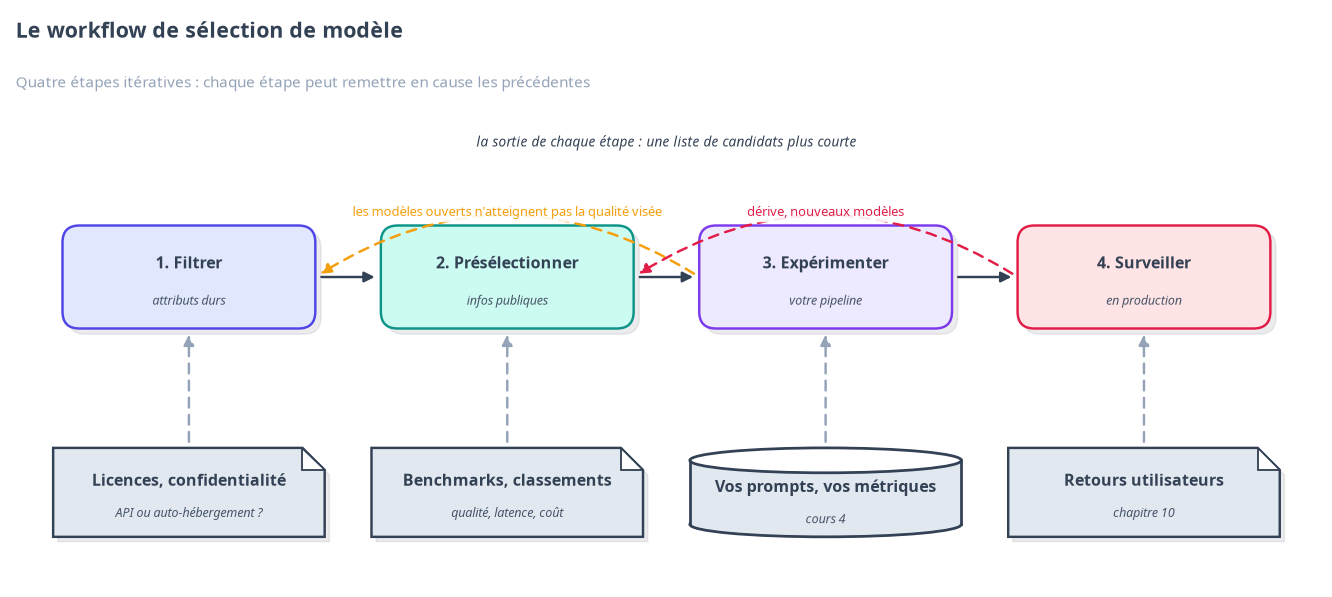

In [2]:
d = Diagram(14, 5.2, title="Le workflow de sélection de modèle",
            subtitle="Quatre étapes itératives : chaque étape peut remettre en cause les précédentes")
d.box("s1", 1.9, 3.3, "1. Filtrer", sub="attributs durs", color=INDIGO, w=2.7, h=1.1)
d.box("s2", 5.3, 3.3, "2. Présélectionner", sub="infos publiques", color=TEAL, w=2.7, h=1.1)
d.box("s3", 8.7, 3.3, "3. Expérimenter", sub="votre pipeline", color=VIOLET, w=2.7, h=1.1)
d.box("s4", 12.1, 3.3, "4. Surveiller", sub="en production", color=ROSE, w=2.7, h=1.1)
d.box("i1", 1.9, 1.0, "Licences, confidentialité", sub="API ou auto-hébergement ?", color=SLATE, kind="doc", w=2.9, h=0.95)
d.box("i2", 5.3, 1.0, "Benchmarks, classements", sub="qualité, latence, coût", color=SLATE, kind="doc", w=2.9, h=0.95)
d.box("i3", 8.7, 1.0, "Vos prompts, vos métriques", sub="cours 4", color=SLATE, kind="db", w=2.9, h=0.95)
d.box("i4", 12.1, 1.0, "Retours utilisateurs", sub="chapitre 10", color=SLATE, kind="doc", w=2.9, h=0.95)
for a, b in [("s1", "s2"), ("s2", "s3"), ("s3", "s4")]:
    d.arrow(a, b)
for a, b in [("i1", "s1"), ("i2", "s2"), ("i3", "s3"), ("i4", "s4")]:
    d.arrow(a, b, style="dashed", color=GRAY)
d.arrow("s3", "s1", "les modèles ouverts n'atteignent pas la qualité visée", style="dashed", color=AMBER, rad=0.32,
        label_offset=(0, 0.05))
d.arrow("s4", "s2", "dérive, nouveaux modèles", style="dashed", color=ROSE, rad=0.32, label_offset=(0, 0.05))
d.note(7.0, 4.75, "la sortie de chaque étape : une liste de candidats plus courte", color=SLATE)
d.show()

> **À retenir.** Filtrez d'abord sur ce qui n'est pas négociable (attributs durs), utilisez
> l'information publique pour présélectionner, tranchez avec votre propre pipeline, puis
> surveillez. La boucle est itérative : une découverte tardive peut rouvrir un choix précoce.

## 2. Filtres durs, attributs souples, front de Pareto (section *Model Selection Workflow*)

Prenons un catalogue fictif de 12 modèles, et une application interne d'une entreprise
européenne avec les exigences dures suivantes : données hébergées en UE (ou poids ouverts,
pour un hébergement interne), usage commercial autorisé, contexte d'au moins 32 000 tokens,
TTFT P90 inférieur à 400 ms.

In [3]:
cat = c4.CATALOGUE.copy()
rules = {
    "données hors UE": lambda d: d.donnees_ue | d.poids_ouverts,
    "licence non commerciale": lambda d: d.usage_commercial,
    "contexte < 32k": lambda d: d.contexte_k >= 32,
    "TTFT P90 > 400 ms": lambda d: d.ttft_p90_ms <= 400,
}
filt = c4.hard_filter(cat, rules)
filt[["modele", "poids_ouverts", "usage_commercial", "contexte_k", "ttft_p90_ms", "donnees_ue",
      "prix_sortie", "qualite", "elimine_par"]]

,modele,poids_ouverts,usage_commercial,contexte_k,ttft_p90_ms,donnees_ue,prix_sortie,qualite,elimine_par
0,Atlas-XL,False,True,200,450,False,15.00,88,données hors UE
1,Atlas-M,False,True,128,220,False,3.00,81,données hors UE
2,Atlas-S,False,True,128,120,False,0.60,72,données hors UE
3,Borealis-70B,True,True,128,300,True,0.90,80,
4,Borealis-8B,True,True,128,90,True,0.20,66,
5,Cirrus-34B,True,False,32,200,True,0.50,76,licence non commerciale
6,Cirrus-7B,True,False,32,80,True,0.15,63,licence non commerciale
7,Delta-Pro,False,True,1000,600,True,10.00,86,TTFT P90 > 400 ms
8,Delta-Flash,False,True,1000,150,True,0.40,74,
9,Equinox-14B,True,True,64,130,True,0.30,71,


Parmi les survivants, la décision porte sur des attributs souples qui s'arbitrent : la
qualité (ici un score interne) contre le coût. Un modèle est **dominé** s'il existe un autre
modèle au moins aussi bon sur les deux axes et strictement meilleur sur l'un. Les modèles non
dominés forment le **front de Pareto** : le seul ensemble où il est rationnel de choisir.

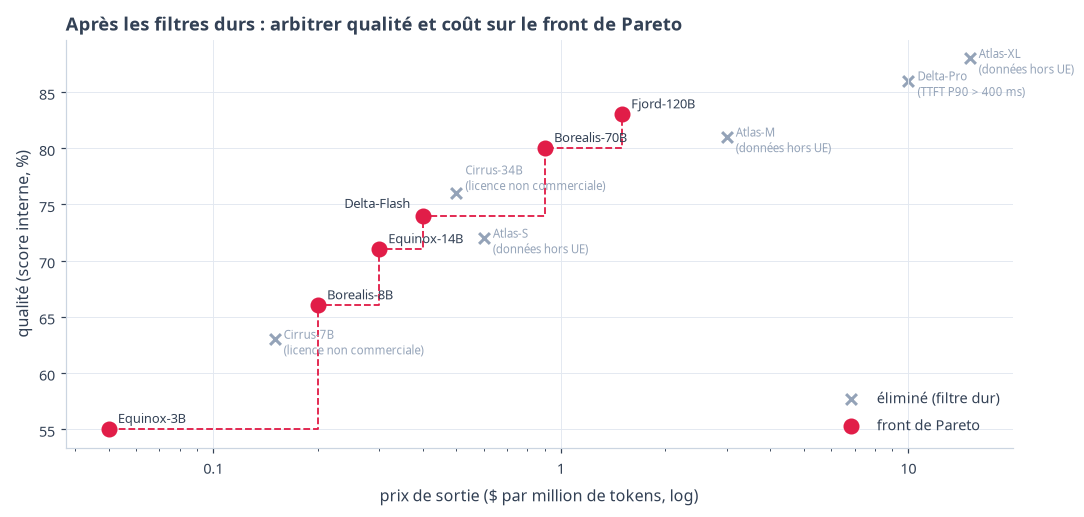

In [4]:
ok = filt[filt.elimine_par == ""].reset_index(drop=True)
front = c4.pareto_front(ok.prix_sortie, ok.qualite)
fig, ax = plt.subplots(figsize=(10, 4.8))
elim = filt[filt.elimine_par != ""]
ax.scatter(elim.prix_sortie, elim.qualite, color=GRAY, s=50, marker="x", label="éliminé (filtre dur)")
for _, r in elim.iterrows():
    ax.annotate(f"{r.modele}\n({r.elimine_par})", (r.prix_sortie, r.qualite), fontsize=7.5, color=GRAY,
                xytext=(6, 2) if r.modele == "Cirrus-34B" else (6, -10), textcoords="offset points")
if (~front).any():
    ax.scatter(ok.prix_sortie[~front], ok.qualite[~front], color=SKY, s=70, label="candidat dominé")
ax.scatter(ok.prix_sortie[front], ok.qualite[front], color=ROSE, s=90, label="front de Pareto", zorder=3)
fr = ok[front].sort_values("prix_sortie")
ax.step(fr.prix_sortie, fr.qualite, where="post", color=ROSE, lw=1.2, ls="--")
for _, r in ok.iterrows():
    left = r.modele in ("Delta-Flash",)
    ax.annotate(r.modele, (r.prix_sortie, r.qualite), fontsize=8.5, xytext=(-8, 5) if left else (6, 4),
                textcoords="offset points", ha="right" if left else "left")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(plain); ax.set_xlabel("prix de sortie ($ par million de tokens, log)")
ax.set_ylabel("qualité (score interne, %)"); ax.legend(loc="lower right")
ax.set_title("Après les filtres durs : arbitrer qualité et coût sur le front de Pareto")
plt.tight_layout(); plt.show()

Le front se lit comme un menu : chaque pas vers la droite achète des points de qualité à un
certain prix. Le choix final dépend de la valeur d'un point de qualité pour votre métier
(cours 4 : relier métriques d'évaluation et métriques métier). Un candidat dominé n'est
jamais le bon choix, sauf attribut non modélisé ici (communauté, support, feuille de route).

> **À retenir.** Filtres durs d'abord (éliminatoires), puis arbitrage multi-objectif sur
> les attributs souples : seul le front de Pareto mérite d'être considéré.

## 3. Open source, poids ouverts et licences (section *Open source, open weight, and model licenses*)

Le terme « open source » est disputé. Le livre distingue les modèles à **poids ouverts**
(*open weight* : on peut télécharger les poids, pas les données) des modèles **ouverts**
(*open model* : données d'entraînement publiques aussi). La plupart des modèles dits
« open source » ne sont qu'à poids ouverts. Les données ouvertes permettent de réentraîner,
d'auditer (le modèle a-t-il été entraîné sur des données illégalement acquises ?) et de
comprendre le modèle.

Les **licences** ajoutent une couche : beaucoup de modèles ont leur propre licence. Trois
questions à se poser systématiquement :

| Question | Exemple cité par le livre |
|---|---|
| L'usage commercial est-il autorisé ? | le premier Llama était sous licence non commerciale |
| S'il l'est, avec quelles restrictions ? | Llama 2 et 3 : licence spéciale au-delà de 700 millions d'utilisateurs actifs mensuels |
| Peut-on utiliser les sorties pour entraîner d'autres modèles ? | important pour la distillation et les données synthétiques (chapitre 8) |

Enfin, la **lignée des données** compte : un modèle entraîné sur les sorties d'un autre
modèle dont la licence l'interdit hérite du problème, quelle que soit sa propre licence.

## 4. API ou auto-hébergement : les sept axes (section *Open source models versus model APIs*)

Un **service d'inférence** héberge le modèle, reçoit les requêtes, exécute le modèle et
renvoie les réponses ; l'interface exposée est l'**API du modèle**. Acheter, c'est utiliser
l'API d'un fournisseur (fournisseur du modèle, cloud, ou tiers qui sert des modèles ouverts) ;
construire, c'est opérer soi-même le service d'inférence.

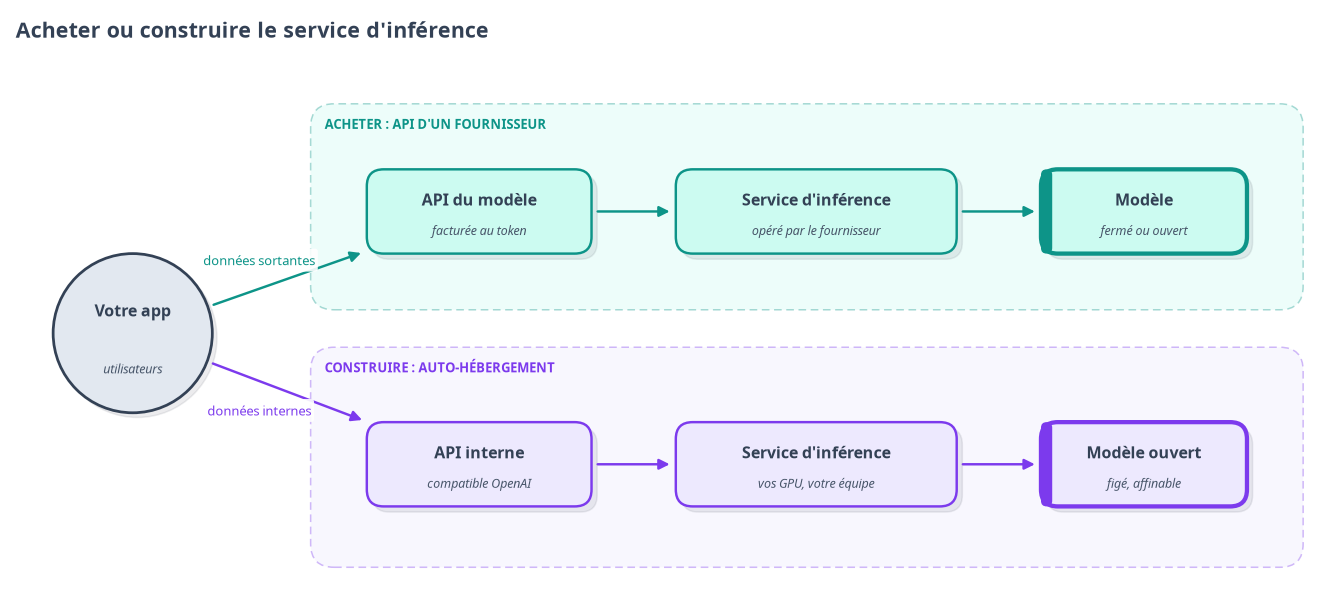

In [5]:
d = Diagram(14, 5.6, title="Acheter ou construire le service d'inférence")
d.group(3.2, 2.95, 13.8, 5.15, "acheter : API d'un fournisseur", color=TEAL)
d.group(3.2, 0.2, 13.8, 2.55, "construire : auto-hébergement", color=VIOLET)
d.box("u", 1.3, 2.7, "Votre app", sub="utilisateurs", color=SLATE, kind="user", w=1.7)
d.box("api1", 5.0, 4.0, "API du modèle", sub="facturée au token", color=TEAL, w=2.4)
d.box("svc1", 8.6, 4.0, "Service d'inférence", sub="opéré par le fournisseur", color=TEAL, w=3.0)
d.box("m1", 12.1, 4.0, "Modèle", sub="fermé ou ouvert", color=TEAL, kind="model", w=2.2)
d.box("api2", 5.0, 1.3, "API interne", sub="compatible OpenAI", color=VIOLET, w=2.4)
d.box("svc2", 8.6, 1.3, "Service d'inférence", sub="vos GPU, votre équipe", color=VIOLET, w=3.0)
d.box("m2", 12.1, 1.3, "Modèle ouvert", sub="figé, affinable", color=VIOLET, kind="model", w=2.2)
d.arrow("u", "api1", "données sortantes", color=TEAL, label_offset=(-0.3, 0.2))
d.arrow("u", "api2", "données internes", color=VIOLET, label_offset=(-0.3, -0.2))
d.arrow("api1", "svc1", color=TEAL); d.arrow("svc1", "m1", color=TEAL)
d.arrow("api2", "svc2", color=VIOLET); d.arrow("svc2", "m2", color=VIOLET)
d.show()

Le livre structure la décision selon sept axes. Résumons-les, puis notons-les pour deux
scénarios contrastés (notes de -2 = favorise fortement l'API à +2 = favorise fortement
l'auto-hébergement ; ces notes sont un exercice de jugement, pas une mesure).

In [6]:
axes7 = pd.DataFrame([
    ("confidentialité", "envoyer des données hors de l'organisation est parfois interdit (fuite Samsung, 2023)", 2, 0),
    ("lignée des données", "API : protection contractuelle ; ouvert : transparence mais peu de recours", -1, -1),
    ("performance", "les meilleurs modèles restent probablement fermés", -1, -2),
    ("fonctionnalités", "API : passage à l'échelle, appel de fonctions ; ouvert : logprobs, affinage", 1, -1),
    ("coût", "API au token ; auto-hébergement : GPU + ingénierie (voir section 5)", 1, -2),
    ("contrôle", "limites de débit, changements de version non annoncés, risque de perte d'accès", 2, -1),
    ("sur appareil", "impossible sans réseau avec une API", 0, 0),
], columns=["axe", "enjeu", "banque (gros volume, données sensibles)", "startup (prototype)"])
axes7[["axe", "enjeu"]]

,axe,enjeu
0,confidentialité,envoyer des données hors de l'organisation est...
1,lignée des données,API : protection contractuelle ; ouvert : tran...
2,performance,les meilleurs modèles restent probablement fermés
3,fonctionnalités,"API : passage à l'échelle, appel de fonctions ..."
4,coût,API au token ; auto-hébergement : GPU + ingéni...
5,contrôle,"limites de débit, changements de version non a..."
6,sur appareil,impossible sans réseau avec une API


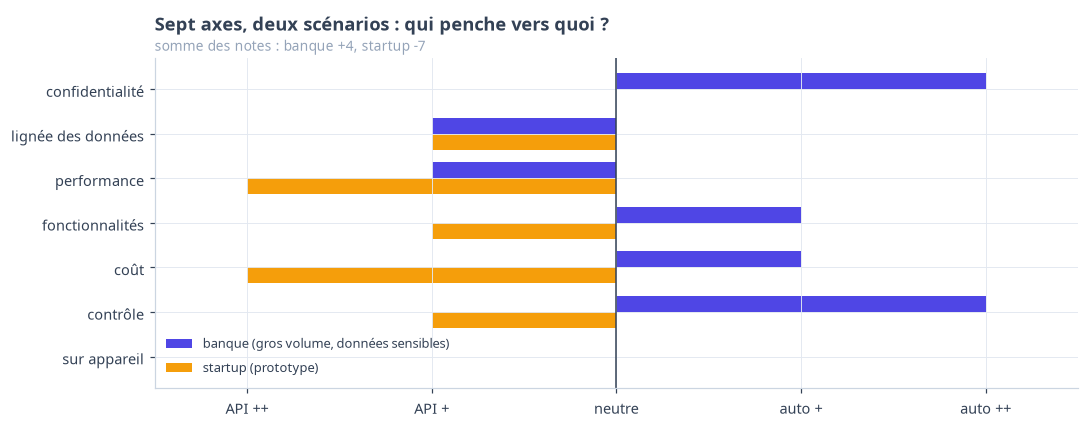

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(axes7))[::-1]
for j, (col, c) in enumerate([("banque (gros volume, données sensibles)", INDIGO), ("startup (prototype)", AMBER)]):
    ax.barh(y + (0.5 - j) * 0.36, axes7[col], height=0.36, color=c, label=col)
ax.axvline(0, color=SLATE, lw=1)
ax.set_yticks(y, axes7.axe); ax.set_xlim(-2.5, 2.5)
ax.set_xticks([-2, -1, 0, 1, 2], ["API ++", "API +", "neutre", "auto +", "auto ++"])
tot = axes7.iloc[:, 2:].sum()
ax.set_title("Sept axes, deux scénarios : qui penche vers quoi ?", pad=18)
ax.legend(loc="lower left", fontsize=8.5)
subtitle(ax, f"somme des notes : banque {tot.iloc[0]:+d}, startup {tot.iloc[1]:+d}")
plt.tight_layout(); plt.show()

La même grille aboutit à deux conclusions opposées : la banque penche vers
l'auto-hébergement (confidentialité, contrôle, volume), la startup vers l'API (meilleure
performance, démarrage immédiat, pas d'équipe d'infrastructure). Et la décision évolue :
la startup qui grossit refera ce calcul, à commencer par l'axe du coût.

> **À retenir.** Construire ou acheter se décide sur sept axes : confidentialité, lignée des
> données, performance, fonctionnalités, coût, contrôle, déploiement sur appareil. La réponse
> dépend de l'équipe, et change avec le temps.

## 5. Construire ou acheter : le calcul du point mort (section *API cost versus engineering cost*)

Formalisons l'axe du coût. Soit $N$ le nombre de requêtes par mois, chacune de $n_{in}$
tokens d'entrée et $n_{out}$ de sortie.

- **API** : coût linéaire, $C_{API}(N) = a\,N$ avec $a = (n_{in}\pi_{in} + n_{out}\pi_{out})/10^6$.
- **Auto-hébergement** : des GPU loués en continu à $h$ $/heure, chacun délivrant
  $D\,u$ tokens/s en moyenne ($D$ débit crête, $u$ taux d'utilisation), plus un coût fixe $F$
  (ingénierie, astreinte, supervision) :
  $$C_{auto}(N) = F + h \cdot 730 \cdot \max\Big(1, \Big\lceil \frac{N(n_{in}+n_{out})}{D\,u \cdot 3600 \cdot 730}\Big\rceil\Big).$$

Deux régimes se dégagent :

- **petit volume** (un seul GPU suffit) : le GPU est payé qu'il serve ou non, le coût
  auto-hébergé est constant, et le point mort vaut $N^*_1 = (F + 730\,h)/a$, valable si
  cette valeur reste sous la capacité d'un GPU ;
- **gros volume** (beaucoup de GPU) : en lissant les marches, chaque requête coûte en moyenne
  $m = \frac{h\,(n_{in}+n_{out})}{3600\,D\,u}$ de GPU, donc $C_{auto} \approx F + mN$ et
  $N^*_\infty \approx F/(a - m)$.

Conséquence capitale : **si $m \geq a$, l'auto-hébergement n'est jamais rentable à grande
échelle**, quel que soit le volume.

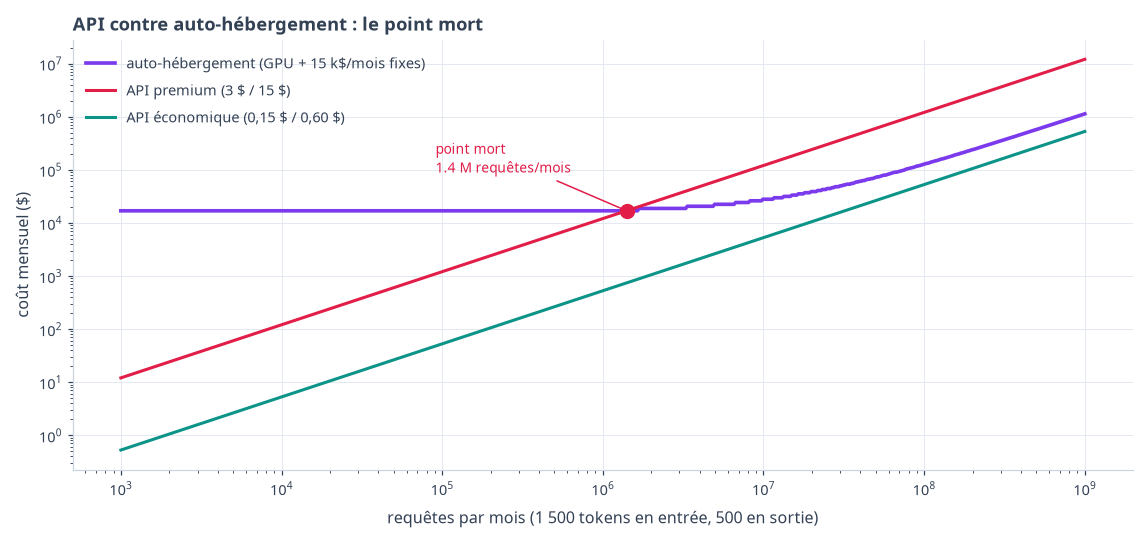

coût marginal auto-hébergé : 1.11 $ / 1000 requêtes
API premium (3 $ / 15 $)            : 12.00 $ / 1000 requêtes
API économique (0,15 $ / 0,60 $)    : 0.53 $ / 1000 requêtes


In [8]:
n_in, n_out = 1500, 500
apis = {"API premium (3 $ / 15 $)": (3.0, 15.0), "API économique (0,15 $ / 0,60 $)": (0.15, 0.60)}
gpu = dict(gpu_hour=2.5, gpu_tokens_per_s=2500, utilization=0.5, fixed_monthly=15_000)
N = np.logspace(3, 9, 600)
f_self = lambda n: c4.selfhost_cost(n, n_in + n_out, **gpu)

fig, ax = plt.subplots(figsize=(10.5, 5))
ax.plot(N, f_self(N), color=VIOLET, lw=2.4, label="auto-hébergement (GPU + 15 k$/mois fixes)")
for (name, (pin, pout)), c in zip(apis.items(), [ROSE, TEAL]):
    f_api = lambda n, pin=pin, pout=pout: c4.api_cost(n, n_in, n_out, pin, pout)
    ax.plot(N, f_api(N), color=c, lw=2, label=name.replace("$", r"\$"))
    be = c4.breakeven(f_api, f_self, 1e3, 1e9)
    if np.isfinite(be):
        ax.plot(be, f_api(be), "o", color=c, ms=9, zorder=4)
        ax.annotate(f"point mort\n{be/1e6:.1f} M requêtes/mois", (be, f_api(be)), xytext=(-125, 25),
                    textcoords="offset points", fontsize=9, color=c, arrowprops=dict(arrowstyle="-", color=c))
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("requêtes par mois (1 500 tokens en entrée, 500 en sortie)"); ax.set_ylabel("coût mensuel ($)")
ax.legend(loc="upper left"); ax.set_title("API contre auto-hébergement : le point mort")
plt.tight_layout(); plt.show()

a = {k: c4.api_cost(1, n_in, n_out, *v) for k, v in apis.items()}
m = gpu["gpu_hour"] * (n_in + n_out) / (3600 * gpu["gpu_tokens_per_s"] * gpu["utilization"])
print(f"coût marginal auto-hébergé : {m*1e3:.2f} $ / 1000 requêtes")
for k, v in a.items():
    print(f"{k:35s} : {v*1e3:.2f} $ / 1000 requêtes")

Lecture : contre l'API premium, l'auto-hébergement devient rentable autour d'un million de
requêtes par mois. Contre l'API économique (un modèle ouvert servi par un tiers, par exemple),
le coût marginal auto-hébergé (1,1 $ pour 1000 requêtes à 50 % d'utilisation) dépasse le prix
de l'API (0,5 $) : **il n'y a pas de point mort**, l'API reste moins chère à tout volume. C'est
exactement la nuance du livre : l'arrivée d'API construites sur des modèles ouverts a rendu
la question bien plus subtile.

Le résultat est très sensible à deux paramètres que l'on connaît mal à l'avance : le coût
fixe d'ingénierie et le taux d'utilisation des GPU.

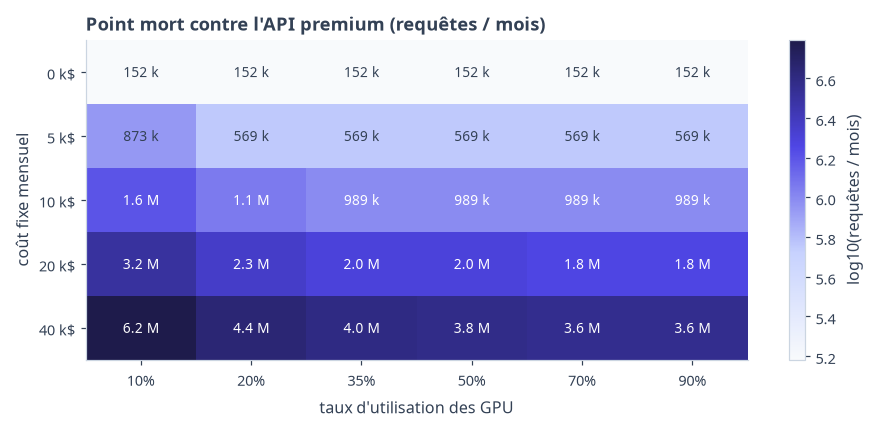

In [9]:
Fs = np.array([0, 5_000, 10_000, 20_000, 40_000])
us = np.array([0.1, 0.2, 0.35, 0.5, 0.7, 0.9])
grid = np.zeros((len(Fs), len(us)))
pin, pout = apis["API premium (3 $ / 15 $)"]
f_api = lambda n: c4.api_cost(n, n_in, n_out, pin, pout)
for i, F in enumerate(Fs):
    for j, u in enumerate(us):
        fs = lambda n, F=F, u=u: c4.selfhost_cost(n, n_in + n_out, gpu_hour=2.5, gpu_tokens_per_s=2500,
                                                  utilization=u, fixed_monthly=F)
        grid[i, j] = c4.breakeven(f_api, fs, 1e2, 1e10)
fig, ax = plt.subplots(figsize=(8.5, 4))
im = ax.imshow(np.log10(grid), cmap="aie_seq", aspect="auto")
ax.set_xticks(range(len(us)), [f"{u:.0%}" for u in us]); ax.set_yticks(range(len(Fs)), [f"{F/1e3:.0f} k$" for F in Fs])
ax.set_xlabel("taux d'utilisation des GPU"); ax.set_ylabel("coût fixe mensuel"); ax.grid(False)
for i in range(len(Fs)):
    for j in range(len(us)):
        v = grid[i, j]
        ax.text(j, i, f"{v/1e3:.0f} k" if v < 1e6 else f"{v/1e6:.1f} M", ha="center", va="center",
                color="white" if np.log10(v) > np.log10(grid).mean() else SLATE, fontsize=9)
ax.set_title("Point mort contre l'API premium (requêtes / mois)")
plt.colorbar(im, ax=ax, label="log10(requêtes / mois)")
plt.tight_layout(); plt.show()

Le coût fixe d'ingénierie domine à faible volume : avec 40 k$/mois d'équipe, il faut des
millions de requêtes pour amortir. Le livre résume : les API sont chères, mais l'ingénierie
peut l'être encore plus. Ce calcul ignore par ailleurs des coûts cachés des deux côtés
(dépendance au SLA d'un fournisseur, garde-fous à construire soi-même).

> **À retenir.** Une API a un coût par token constant ; l'auto-hébergement a un coût fixe
> élevé et un coût marginal faible. Le point mort vaut $(F + 730h)/a$ tant qu'un GPU suffit,
> environ $F/(a-m)$ à grande échelle, et n'existe que si le coût marginal $m$ est inférieur au
> prix de l'API $a$.

## 6. Agréger des benchmarks en classement (section *Benchmark selection and aggregation*)

Il existe des milliers de benchmarks (BIG-bench en compte 214 à lui seul) ; les harnais
d'évaluation (`lm-evaluation-harness`, plus de 400 benchmarks ; OpenAI `evals`) permettent de
les exécuter. Un **classement** (*leaderboard*) agrège les résultats de quelques
benchmarks. Deux questions : lesquels inclure, et comment agréger ?

Trois agrégations courantes pour un modèle $i$ et des benchmarks $b = 1..B$ :

- la **moyenne brute** (Open LLM Leaderboard de Hugging Face) : $\bar s_i = \frac1B\sum_b s_{ib}$.
  Elle traite 80 % sur TruthfulQA comme 80 % sur GSM-8K, alors que l'un peut être bien plus
  difficile à atteindre ;
- le **taux de victoire moyen** (HELM) : la fraction des autres modèles battus, moyennée sur
  les benchmarks, $\text{MWR}_i = \frac1B\sum_b \frac{\#\{j : s_{ib} > s_{jb}\}}{n-1}$ ;
- la **moyenne des z-scores** : $\frac1B\sum_b (s_{ib} - \mu_b)/\sigma_b$, qui met les
  benchmarks à la même échelle, éventuellement pondérée selon vos priorités.

On simule 30 modèles sur les 6 benchmarks de l'Open LLM Leaderboard, avec la structure de
corrélation réelle (tableau 4-5) mais des moyennes et dispersions différentes par benchmark.

In [10]:
lb = c4.synthetic_leaderboard(30, seed=3)
rank = pd.DataFrame({
    "moyenne": lb.mean(axis=1).rank(ascending=False),
    "taux de victoire": c4.mean_win_rate(lb).rank(ascending=False),
    "z-score": c4.zscore_mean(lb).rank(ascending=False),
    "z pondéré (maths x3)": c4.zscore_mean(lb, weights=[1, 1, 1, 1, 1, 3]).rank(ascending=False),
})
taus = pd.DataFrame([[kendalltau(rank[a], rank[b])[0] for b in rank] for a in rank], index=rank.columns, columns=rank.columns)
print("Dispersion des scores par benchmark (écart-type, points) :", lb.std().round(1).to_dict())
taus.round(2)

Dispersion des scores par benchmark (écart-type, points) : {'ARC-C': 9.8, 'HellaSwag': 5.4, 'MMLU': 12.2, 'TruthfulQA': 8.6, 'WinoGrande': 7.4, 'GSM-8K': 20.3}


,moyenne,taux de victoire,z-score,z pondéré (maths x3)
moyenne,1.00,0.9,0.89,0.98
taux de victoire,0.90,1.0,0.90,0.90
z-score,0.89,0.9,1.00,0.89
z pondéré (maths x3),0.98,0.9,0.89,1.00


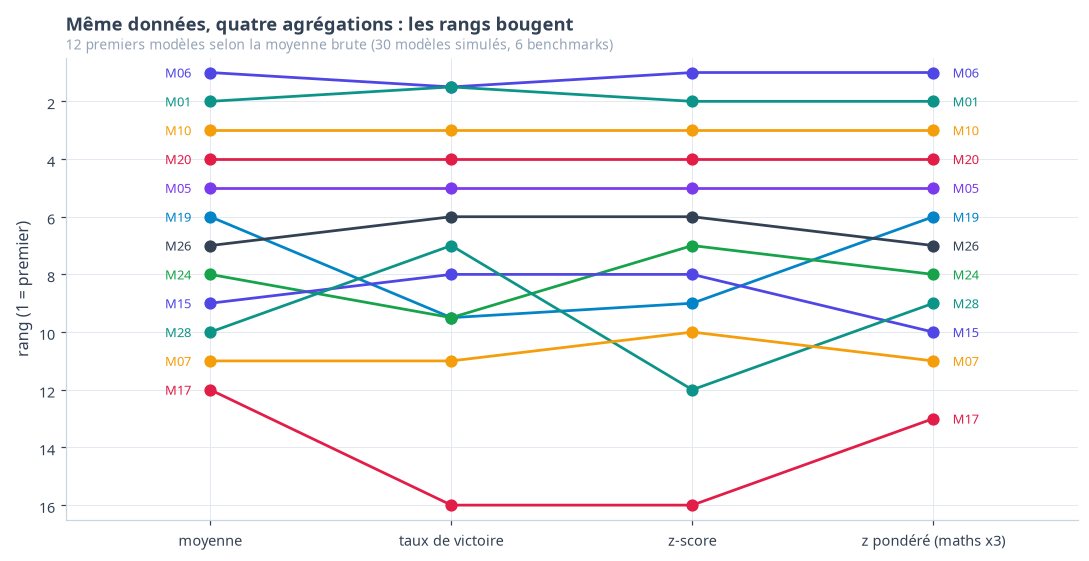

In [11]:
top = rank.sort_values("moyenne").head(12).index
fig, ax = plt.subplots(figsize=(10, 5.2))
cols = list(rank.columns)
for k, mname in enumerate(top):
    r = rank.loc[mname, cols].values
    c = COLORS[k % len(COLORS)]
    ax.plot(range(len(cols)), r, "o-", color=c, lw=1.8, ms=7)
    ax.text(-0.08, r[0], mname, ha="right", va="center", fontsize=8.5, color=c)
    ax.text(len(cols) - 1 + 0.08, r[-1], mname, ha="left", va="center", fontsize=8.5, color=c)
ax.set_xticks(range(len(cols)), cols); ax.set_ylim(rank.loc[top].values.max() + 0.5, 0.5)
ax.set_ylabel("rang (1 = premier)"); ax.set_xlim(-0.6, len(cols) - 0.4)
ax.set_title("Même données, quatre agrégations : les rangs bougent", pad=18)
subtitle(ax, "12 premiers modèles selon la moyenne brute (30 modèles simulés, 6 benchmarks)")
plt.tight_layout(); plt.show()

Les agrégations s'accordent globalement (tau de Kendall élevé), mais les rangs individuels
bougent de plusieurs places, surtout dans le peloton de tête où les écarts sont faibles.
La moyenne brute surpondère implicitement les benchmarks les plus dispersés (ici GSM-8K) ;
les z-scores corrigent cela ; la pondération exprime vos priorités. Pour votre application,
vous construisez en réalité un **classement privé** : choisissez des benchmarks pertinents
(du code pour un agent de programmation), récents (les anciens saturent), et fiables.

> **À retenir.** Un classement dépend autant de la façon d'agréger que des données :
> moyenne brute, taux de victoire moyen et z-scores donnent des rangs différents. Pondérez
> selon les capacités qui comptent pour vous.

## 7. Les corrélations entre benchmarks

Si deux benchmarks sont parfaitement corrélés, l'un des deux est inutile ; s'ils sont
fortement corrélés, les inclure tous deux **double le poids** d'une même capacité et amplifie
les biais. Le tableau 4-5 du livre (corrélations de Pearson entre les six benchmarks de
l'Open LLM Leaderboard, janvier 2024) montre un bloc ARC-C / MMLU / WinoGrande très corrélé
(raisonnement), tandis que TruthfulQA est à part.

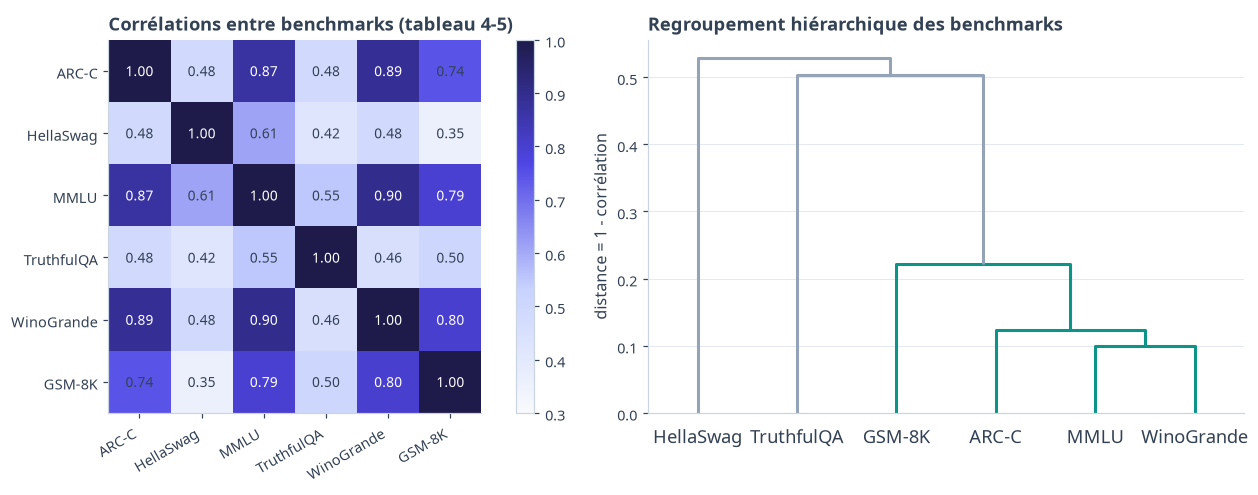

In [12]:
C = c4.HF_CORR
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1.15, 1]))
im = axes[0].imshow(C.values, cmap="aie_seq", vmin=0.3, vmax=1)
axes[0].set_xticks(range(6), C.columns, rotation=30, ha="right"); axes[0].set_yticks(range(6), C.index)
axes[0].grid(False)
for i in range(6):
    for j in range(6):
        axes[0].text(j, i, f"{C.values[i, j]:.2f}", ha="center", va="center", fontsize=9,
                     color="white" if C.values[i, j] > 0.75 else SLATE)
axes[0].set_title("Corrélations entre benchmarks (tableau 4-5)")
plt.colorbar(im, ax=axes[0], fraction=0.046)
Z = linkage(squareform(1 - C.values, checks=False), method="average")
dendrogram(Z, labels=list(C.columns), ax=axes[1], color_threshold=0.3, above_threshold_color=GRAY)
axes[1].set_ylabel("distance = 1 - corrélation"); axes[1].grid(axis="x", visible=False)
axes[1].set_title("Regroupement hiérarchique des benchmarks")
finish(fig)

**Combien de benchmarks « effectifs » ?** Les valeurs propres $\lambda_k$ de la matrice de
corrélation mesurent la variance portée par chaque direction indépendante. Un indicateur
classique est le **nombre effectif** (ratio de participation)
$$B_{\text{eff}} = \frac{\left(\sum_k \lambda_k\right)^2}{\sum_k \lambda_k^2},$$
qui vaut $B$ si les benchmarks sont indépendants et 1 s'ils sont parfaitement corrélés.

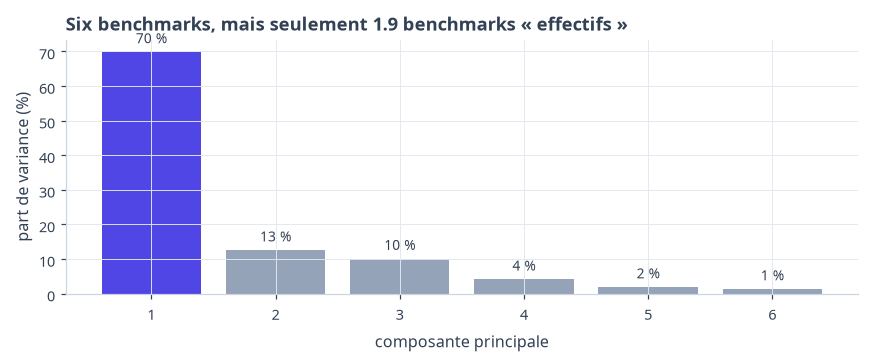

In [13]:
lam = np.sort(np.linalg.eigvalsh(C.values))[::-1]
b_eff = lam.sum() ** 2 / (lam**2).sum()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(range(1, 7), lam / lam.sum() * 100, color=[INDIGO] + [GRAY] * 5)
annotate_bars(ax, "{:.0f} %")
ax.set_xlabel("composante principale"); ax.set_ylabel("part de variance (%)")
ax.set_title(f"Six benchmarks, mais seulement {b_eff:.1f} benchmarks « effectifs »")
plt.tight_layout(); plt.show()

Une seule direction (une sorte de « capacité générale ») explique la majorité de la
variance : moyenner ces six benchmarks revient surtout à mesurer cette capacité, avec un
poids triple pour le raisonnement. Le livre note qu'une absence totale de corrélation entre
deux métriques est aussi informative : soit une vraie indépendance des capacités, soit une
métrique peu fiable.

> **À retenir.** Regardez les corrélations avant d'agréger : des benchmarks très corrélés
> n'apportent pas d'information nouvelle et surpondèrent une capacité.

## 8. La contamination des données (section *Data contamination with public benchmarks*)

Il y a **contamination** quand un modèle a été entraîné sur les données sur lesquelles on
l'évalue : il peut alors réciter au lieu de raisonner. L'article satirique *Pretraining on
the Test Set Is All You Need* (Schaeffer, 2023) obtient des scores quasi parfaits avec un
modèle d'un million de paramètres entraîné sur les benchmarks eux-mêmes. La contamination est
surtout **involontaire** : les données web aspirées contiennent les benchmarks publiés, ou des
sources communes (manuels de maths) servent à la fois à l'entraînement et à la création de
benchmarks. Deux heuristiques de détection :

- le **recouvrement de n-grammes** : si une séquence de 13 tokens d'un exemple d'évaluation
  figure dans les données d'entraînement, l'exemple est « sale ». Précis, mais il faut accéder
  aux données d'entraînement et tout comparer ;
- la **perplexité** : une perplexité anormalement basse sur un texte suggère que le modèle
  l'a déjà vu. Moins précis, mais ne demande que le modèle.

**Recouvrement de n-grammes.** On fabrique un petit « corpus d'entraînement » qui contient
mot pour mot deux questions d'un benchmark jouet, une version paraphrasée d'une troisième, et
pas la quatrième.

In [14]:
bench = {
    "Q1 (copiée)": "Un train part de Paris à 8 heures et roule à 120 kilomètres par heure ; à quelle heure arrive-t-il à Lyon situé à 480 kilomètres ?",
    "Q2 (copiée)": "Quelle est la probabilité d'obtenir deux fois pile en lançant trois fois une pièce équilibrée et indépendante ?",
    "Q3 (paraphrasée)": "Combien de façons existe-t-il de ranger cinq livres différents sur une étagère qui ne contient qu'une seule rangée ?",
    "Q4 (absente)": "Un rectangle a un périmètre de 30 centimètres et une longueur double de sa largeur ; quelle est son aire ?",
}
corpus = " ".join([
    "Voici quelques exercices corrigés trouvés sur un forum de mathématiques.",
    bench["Q1 (copiée)"], "La réponse est midi car le trajet dure quatre heures.",
    "Exercice suivant :", bench["Q2 (copiée)"], "On trouve trois huitièmes.",
    "De combien de manières peut-on disposer cinq livres distincts sur une étagère à une seule rangée ? Réponse : 120.",
    "Le reste de la page parle de géométrie dans l'espace et de vecteurs.",
])
rows = []
for n in [4, 8, 13]:
    grams = c4.ngrams(c4.simple_tokenize(corpus), n)
    for k, q in bench.items():
        rows.append(dict(question=k, n=n, recouvrement=c4.ngram_overlap(q, grams, n)))
ov = pd.DataFrame(rows).pivot(index="question", columns="n", values="recouvrement")
ov.columns = [f"{n}-grammes" for n in ov.columns]
(ov * 100).round(0)

,4-grammes,8-grammes,13-grammes
question,,,
Q1 (copiée),100.0,100.0,100.0
Q2 (copiée),100.0,100.0,100.0
Q3 (paraphrasée),0.0,0.0,0.0
Q4 (absente),0.0,0.0,0.0


Les copies mot pour mot sont détectées à toutes les longueurs de n-gramme ; la paraphrase
échappe à la détection, même avec des 4-grammes, alors que le contenu est identique. Le choix de
$n$ arbitre entre faux positifs (n petit : des expressions banales sont partagées) et faux
négatifs (n grand : la moindre reformulation passe).

**Perplexité.** Sans accès aux données d'entraînement, on compare la perplexité de Qwen 0.5B
sur des textes célèbres (très probablement dans ses données) et sur des **paraphrases** de ces
mêmes textes, de contenu équivalent mais jamais vues telles quelles.

In [15]:
pairs = [
    ("Déclaration d'indépendance",
     "We hold these truths to be self-evident, that all men are created equal, that they are endowed by their Creator with certain unalienable Rights, that among these are Life, Liberty and the pursuit of Happiness.",
     "We consider these facts to be obvious, that all people are made equal, that their Creator gave them some rights that cannot be taken away, among which are life, freedom and the search for happiness."),
    ("Hamlet",
     "To be, or not to be, that is the question: Whether 'tis nobler in the mind to suffer the slings and arrows of outrageous fortune, or to take arms against a sea of troubles.",
     "To live or to die, this is what I wonder: whether it is nobler to endure the blows of terrible luck, or to fight against an ocean of problems."),
    ("Lorem ipsum",
     "Lorem ipsum dolor sit amet, consectetur adipiscing elit, sed do eiusmod tempor incididunt ut labore et dolore magna aliqua.",
     "Lorem dolor ipsum amet sit, adipiscing consectetur elit, eiusmod sed tempor do ut incididunt dolore labore magna et aliqua."),
    ("Zen de Python",
     "Beautiful is better than ugly. Explicit is better than implicit. Simple is better than complex. Complex is better than complicated.",
     "Pretty is preferable to ugly. Clear is preferable to hidden. Easy is preferable to complex. Complex is preferable to complicated."),
    ("DDHC, article 1",
     "Les hommes naissent et demeurent libres et égaux en droits. Les distinctions sociales ne peuvent être fondées que sur l'utilité commune.",
     "Les êtres humains naissent et restent libres et égaux en droits. Les différences sociales ne peuvent reposer que sur l'intérêt général."),
]
pp = pd.DataFrame([dict(texte=n, original=llm.perplexity(o, llm.SMALL), paraphrase=llm.perplexity(p, llm.SMALL))
                   for n, o, p in pairs]).set_index("texte")
pp["ratio"] = pp.paraphrase / pp.original
pp.round(1)

,original,paraphrase,ratio
texte,,,
Déclaration d'indépendance,1.5,21.5,14.3
Hamlet,2.2,42.7,19.5
Lorem ipsum,2.0,113.3,57.1
Zen de Python,4.5,15.0,3.3
"DDHC, article 1",30.9,18.6,0.6


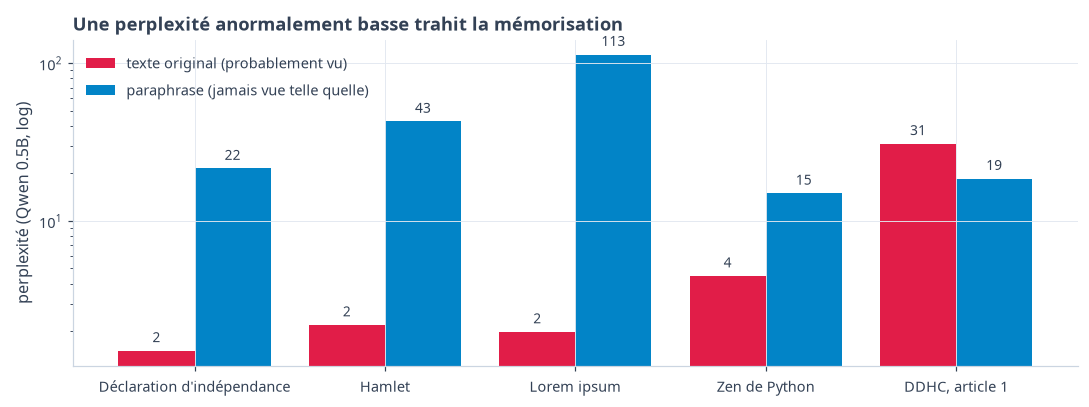

In [16]:
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(pp))
ax.bar(x - 0.2, pp.original, width=0.4, color=ROSE, label="texte original (probablement vu)")
ax.bar(x + 0.2, pp.paraphrase, width=0.4, color=SKY, label="paraphrase (jamais vue telle quelle)")
annotate_bars(ax, "{:.0f}")
ax.set_yscale("log"); ax.set_xticks(x, pp.index); ax.set_ylabel("perplexité (Qwen 0.5B, log)")
ax.legend(loc="upper left"); ax.set_title("Une perplexité anormalement basse trahit la mémorisation")
plt.tight_layout(); plt.show()

Pour les textes anglais et latins très diffusés, la perplexité de l'original est d'un ordre de
grandeur inférieure à celle de la paraphrase : le modèle les a mémorisés. L'article 1 de la
Déclaration des droits de l'homme fait exception : ce petit modèle, surtout entraîné sur de
l'anglais et du chinois, ne l'a manifestement pas mémorisé mot pour mot (la paraphrase, plus
simple, est même moins surprenante). La méthode ne détecte que ce qui a été **mémorisé**, pas
tout ce qui a été vu. Pour un benchmark, on comparerait de même la perplexité des
questions publiées à celle de questions reformulées ou nouvellement écrites. La méthode
reste grossière : une paraphrase est aussi, par construction, moins « canonique », et donc
un peu plus surprenante.

**Effet sur les scores.** OpenAI a trouvé 13 benchmarks dont au moins 40 % des exemples
figuraient dans les données de GPT-3, et a comparé le score sur l'ensemble au score sur les
seuls exemples propres (figure 4-10 du livre). Simulons : un modèle réussit les exemples
propres avec une probabilité $p$, les exemples contaminés avec $p + \beta$ (bonus de
mémorisation), et une fraction $f$ du benchmark est contaminée.

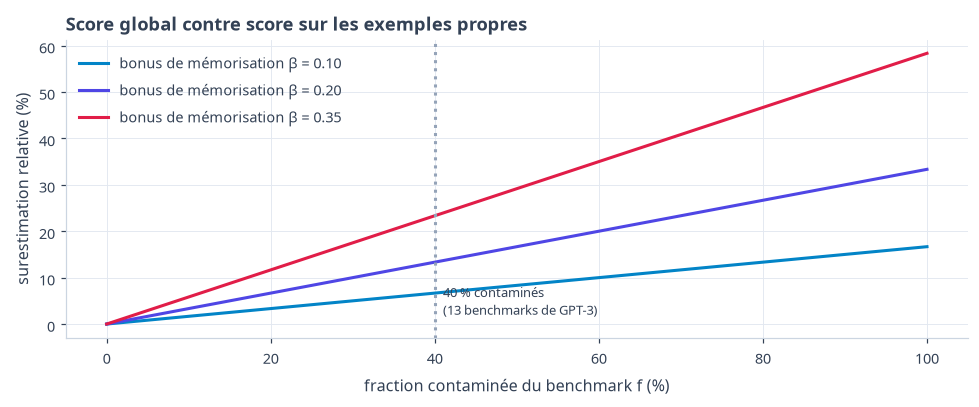

In [17]:
p0 = 0.6
fs = np.linspace(0, 1, 101)
fig, ax = plt.subplots(figsize=(9, 3.8))
for beta, c in [(0.1, SKY), (0.2, INDIGO), (0.35, ROSE)]:
    overall = (1 - fs) * p0 + fs * min(p0 + beta, 1)
    ax.plot(fs * 100, (overall - p0) / p0 * 100, color=c, label=f"bonus de mémorisation β = {beta:.2f}")
ax.axvline(40, color=GRAY, ls=":")
ax.text(41, 2, "40 % contaminés\n(13 benchmarks de GPT-3)", fontsize=8.5, color=SLATE)
ax.set_xlabel("fraction contaminée du benchmark f (%)")
ax.set_ylabel("surestimation relative (%)")
ax.set_title("Score global contre score sur les exemples propres")
ax.legend(); plt.tight_layout(); plt.show()

La surestimation relative vaut $f\beta/p$ : elle croît linéairement avec la contamination
et le bonus de mémorisation. D'où les bonnes pratiques du livre : publier la fraction
contaminée et le score sur la partie propre ; garder une partie privée des benchmarks ;
surveiller les modèles dont les scores sont anormalement élevés (Hugging Face trace les
écarts-types pour repérer les valeurs aberrantes). La contamination peut aussi être
volontaire et légitime : entraîner le modèle final sur des données de benchmark de bonne
qualité améliore le produit, au prix de la comparabilité.

> **À retenir.** Les benchmarks publics sont probablement contaminés. On la détecte par
> recouvrement de n-grammes (précis, demande les données) ou par perplexité (grossier, demande
> seulement le modèle) ; la surestimation vaut environ $f\beta/p$.

## 9. La saturation des benchmarks

Un benchmark **sature** quand les meilleurs modèles atteignent son plafond : il ne
discrimine plus. Le livre le constate en direct : en juin 2024, Hugging Face a remplacé
l'ensemble de son classement (GSM-8K par MATH niveau 5, MMLU par MMLU-PRO, ajout de GPQA, MuSR,
BBH, IFEval). On peut quantifier la saturation : sur un benchmark de $n$ questions, l'écart
type d'échantillonnage d'un score $p$ vaut $\sqrt{p(1-p)/n}$. Quand l'écart entre les
meilleurs modèles devient comparable à ce bruit, le classement en tête n'est plus que du
hasard.

Simulation : chaque année, le « niveau » des 10 meilleurs modèles progresse ; le score sur un
benchmark de difficulté $\delta$ suit une courbe en S entre le hasard (25 %) et un plafond
(97 %, les erreurs d'annotation empêchant d'atteindre 100 %).

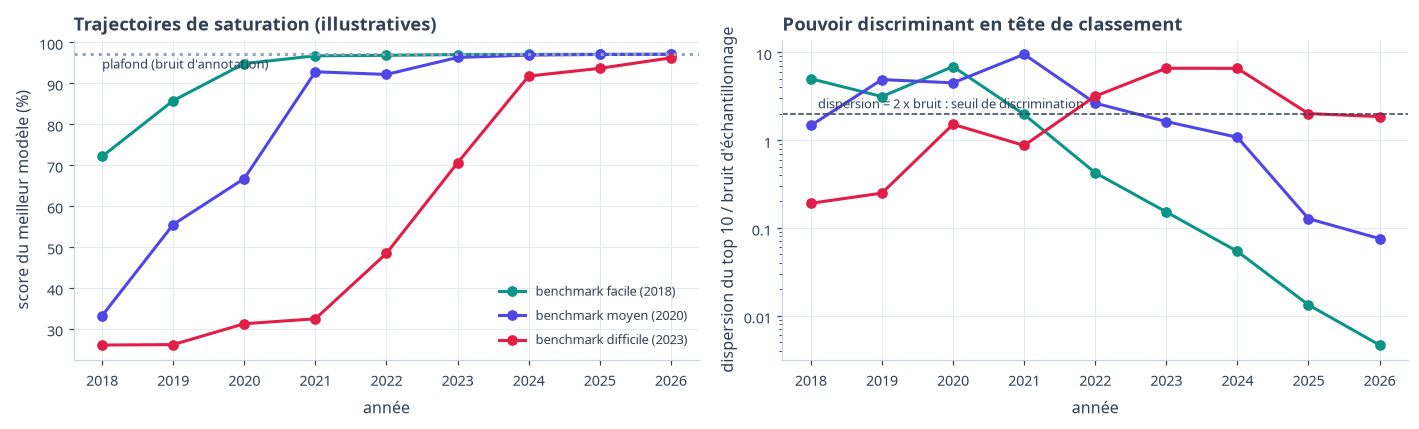

In [18]:
years = np.arange(2018, 2027)
bench_diff = {"benchmark facile (2018)": 0.0, "benchmark moyen (2020)": 2.0, "benchmark difficile (2023)": 4.5}
n_items = 1000
rng = np.random.default_rng(1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (name, delta), c in zip(bench_diff.items(), [TEAL, INDIGO, ROSE]):
    ability = (years - 2018) * 0.9                       # progrès du niveau moyen des meilleurs modèles
    top10 = ability[:, None] + rng.normal(0, 0.5, (len(years), 10))
    acc = c4.logistic_saturation(top10, t0=delta, rate=1.4, floor=25, ceiling=97) / 100
    axes[0].plot(years, acc.max(1) * 100, "o-", color=c, label=name)
    spread = acc.std(1) * 100
    se = np.sqrt(acc.mean(1) * (1 - acc.mean(1)) / n_items) * 100
    axes[1].plot(years, spread / se, "o-", color=c, label=name)
axes[0].axhline(97, color=GRAY, ls=":"); axes[0].text(2018, 93.5, "plafond (bruit d'annotation)", fontsize=8.5)
axes[0].set_xlabel("année"); axes[0].set_ylabel("score du meilleur modèle (%)")
axes[0].set_title("Trajectoires de saturation (illustratives)"); axes[0].legend(fontsize=8.5)
axes[1].axhline(2, color=SLATE, ls="--", lw=1)
axes[1].text(2018.1, 2.3, "dispersion = 2 x bruit : seuil de discrimination", fontsize=8.5)
axes[1].set_yscale("log"); axes[1].yaxis.set_major_formatter(plain); axes[1].set_xlabel("année")
axes[1].set_ylabel("dispersion du top 10 / bruit d'échantillonnage")
axes[1].set_title("Pouvoir discriminant en tête de classement")
finish(fig)

Chaque benchmark passe par trois phases : trop difficile (tout le monde est proche du hasard,
rapport faible), utile (les modèles s'étalent, rapport élevé), saturé (tout le monde frôle le
plafond, le rapport retombe). D'où la course aux nouveaux benchmarks, de plus en plus durs :
en deux ans, on est passé de questions de niveau collège à des questions de niveau doctorat
(GPQA). Le livre rêve d'un benchmark « sans fin », dont les problèmes seraient générés à mesure
que les modèles progressent.

> **À retenir.** Un benchmark saturé ne départage plus les meilleurs modèles : comparez
> l'écart entre modèles au bruit d'échantillonnage $\sqrt{p(1-p)/n}$ avant de lire un
> classement.

## Synthèse

- **Workflow** : filtrer sur les attributs durs, présélectionner avec l'information publique,
  trancher avec son propre pipeline, surveiller ; itératif.
- **Arbitrage** : filtres éliminatoires puis front de Pareto sur les attributs souples.
- **Construire ou acheter** : sept axes ; pour le coût, un point mort
  ($(F + 730h)/a$ avec un GPU, $F/(a - m)$ à grande échelle) qui n'existe que si le coût
  marginal auto-hébergé $m$ est inférieur au prix de l'API $a$.
- **Benchmarks publics** : l'agrégation (moyenne, taux de victoire, z-scores) change les rangs ;
  les benchmarks corrélés surpondèrent une capacité ; la contamination gonfle les scores
  d'environ $f\beta/p$ ; la saturation tue le pouvoir discriminant.
- Les benchmarks publics servent à **éliminer les mauvais modèles**, pas à trouver le meilleur
  pour vous : c'est le rôle du pipeline d'évaluation privé (cours 4).

Liens : coût et latence de l'inférence (chapitre 9), affinage des modèles ouverts (chapitre 7),
données synthétiques et licences de sortie (chapitre 8), retours utilisateurs (chapitre 10).

In [19]:
llm.free_gpu()